# Session 1 · Getting to know Food-101

Before training anything, I want to know which photos I can learn from, what the model will actually see after cropping, and how long one training pass will take on my hardware. Food-101 labels the dish in each photo. A packaged product would need a different label, such as its brand and pack size.

The authors give each dish 750 training photos and 250 manually reviewed test photos. They deliberately kept the training set noisy. I use the official test membership and build my validation set from the training pool. Validation is the practice set for choosing settings. The test set is reserved for scoring the final choice. [Food-101 dataset and paper](https://data.vision.ee.ethz.ch/cvl/datasets_extra/food-101/)

The larger experiment is about **transfer learning**. A pretrained model starts with weights it learned on another dataset, here ImageNet, a large labeled image collection. The backbone turns pixels into features. The classifier head turns those features into one score per dish. In this session I only measure the cost of training; I will fit the first baseline in Session 2.

The saved outputs below come from my Windows CPU audit. I can open this notebook in Colab to review the same evidence. If I rerun the audit there, its outputs go into a separate rerun directory. Session 02 reads the original frozen manifest.

In [1]:
from pathlib import Path
from time import perf_counter
import hashlib
import json
import platform
import random
import statistics

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
import torch
import torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights

from pathlib import Path
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive/Colab Notebooks/Project 03 - Intelligent Food and Retail Product Recognition")
    sys.path.insert(0, str(PROJECT))
    from colab_food101 import stage_food
    ROOT = stage_food(PROJECT, Path("/content/project03_data"))
else:
    PROJECT = Path.cwd()
    ROOT = PROJECT / "Dataset/food-101"
ART = PROJECT / "Artifacts"
if IN_COLAB:
    ART = ART / "session01_colab_rerun"
ART.mkdir(exist_ok=True, parents=True)
SEED = 42

def save_json(name, value):
    (ART / name).write_text(json.dumps(value, indent=2) + "\n", encoding="utf-8")

print(f"PyTorch {torch.__version__}, torchvision {torchvision.__version__}")
print("Dataset directory:", ROOT.resolve())

Matplotlib is building the font cache; this may take a moment.


PyTorch 2.13.0+cpu, torchvision 0.28.0+cpu
Dataset directory: D:\2. Skill Development\Deep Learning Projects\03_Intelligent_Food_and_Retail_Product_Recognition\Dataset\food-101


## Check the labels against the files

I use the authors' lists directly because I want to inspect every assignment. Torchvision's Food101 loader is a convenient alternative when I just need images and class IDs. A **class map** gives each dish a fixed number so that score 0 always means the same dish, even after exporting the model. The file check can detect a missing image or an inconsistent label. Confirming that the food itself matches the label requires visual review. [Torchvision Food101](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.Food101.html)

In [2]:
def read_list(name):
    return (ROOT / "meta" / f"{name}.txt").read_text(encoding="utf-8").splitlines()

classes = sorted(read_list("classes"))
assert len(classes) == len(set(classes)) == 101
class_map = {name: index for index, name in enumerate(classes)}
rows = []
for official_split in ("train", "test"):
    items = read_list(official_split)
    for item in items:
        dish, image_id = item.split("/")
        assert dish in class_map and image_id.isdigit(), item
        rows.append((f"images/{item}.jpg", dish, class_map[dish], official_split))

data = pd.DataFrame(rows, columns=["path", "dish", "class_id", "official_split"])
assert data.path.is_unique
official_counts = pd.crosstab(data.dish, data.official_split)
assert set(official_counts.index) == set(classes)
assert official_counts["train"].eq(750).all() and official_counts["test"].eq(250).all()
disk_paths = {p.relative_to(ROOT).as_posix() for p in (ROOT / "images").glob("*/*.jpg")
              if not p.name.startswith("._")}
assert set(data.path) == disk_paths, "The metadata and extracted image files differ."
save_json("class_map.json", class_map)
print(data.groupby("official_split").size().to_string())
print(f"{len(class_map)} dish labels; first five: {classes[:5]}")

official_split
test     25250
train    75750
101 dish labels; first five: ['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare']


## Find identical photos before splitting

A duplicate in both training and validation can reward memorization. I decode every photo to RGB and hash its dimensions and pixel values. A **hash** is a short fingerprint. This catches identical pixels even when JPEG metadata differs. An alternative is a perceptual hash, which can also flag resized or edited copies but needs a review threshold. This audit covers exact RGB matches. I read test pixels only for this integrity check. All examples and model updates below use training photos.

In [3]:
from concurrent.futures import ThreadPoolExecutor

def inspect_photo(relative_path):
    with Image.open(ROOT / relative_path) as image:
        mode = image.mode
        rgb = image.convert("RGB")
        width, height = rgb.size
        digest = hashlib.sha256(f"{width}x{height}:".encode("ascii"))
        digest.update(rgb.tobytes())
        return width, height, mode, digest.hexdigest()

# Each worker reads one independent file. map preserves the manifest's row order.
with ThreadPoolExecutor(max_workers=4) as pool:
    audit = []
    for offset in range(0, len(data), 256):
        audit.extend(pool.map(inspect_photo, data.path.iloc[offset:offset + 256]))
data[["width", "height", "mode", "pixel_sha256"]] = pd.DataFrame(audit, index=data.index)
groups = data.groupby("pixel_sha256")
duplicates = groups.size()
test_hashes = set(data.loc[data.official_split.eq("test"), "pixel_sha256"])
conflicts = set(groups.dish.nunique().loc[lambda counts: counts.gt(1)].index)
print("Images decoded:", len(data))
print("Source color modes:", data["mode"].value_counts().to_dict())
print("Exact-duplicate groups:", int(duplicates.gt(1).sum()))
print("Photos in duplicate groups:", int(duplicates[duplicates.gt(1)].sum()))
print("Groups with multiple dish labels:", len(conflicts))

Images decoded: 101000
Source color modes: {'RGB': 100997, 'L': 3}
Exact-duplicate groups: 58
Photos in duplicate groups: 118
Groups with multiple dish labels: 2


## Freeze a class-balanced split

I set aside 100 eligible training photos per dish. This is a **stratified split**, which means every dish has representation in validation. A plain random split is simpler, but some classes can end up with more influence. I keep identical photos together. If an official training photo matches a test photo, or identical pixels carry conflicting labels, I exclude that training photo and record why. The manifest is a table with one row per image. Later notebooks can read it without drawing a new split.

The seed fixes the pseudorandom order of duplicate groups. I also save the actual split because the seed alone cannot describe later changes to the files or the splitting code.

In [4]:
data["split"] = data.official_split.copy()
data["exclusion_reason"] = ""
in_pool = data.official_split.eq("train")
for hashes, reason in [(conflicts, "conflicting_labels"), (test_hashes, "matches_official_test")]:
    affected = in_pool & data.pixel_sha256.isin(hashes)
    data.loc[affected, ["split", "exclusion_reason"]] = ["excluded", reason]

rng = random.Random(SEED)
eligible = data[data.split.eq("train")]
for dish, frame in eligible.groupby("dish", sort=True):
    sizes = list(frame.groupby("pixel_sha256", sort=True).size().items())
    rng.shuffle(sizes)
    remaining = 100
    selected = set()
    for fingerprint, count in sizes:
        if count <= remaining:
            selected.add(fingerprint)
            remaining -= count
        if remaining == 0:
            break
    assert remaining == 0, f"Could not reach validation target for {dish}"
    data.loc[frame.index[frame.pixel_sha256.isin(selected)], "split"] = "validation"

usable = data[data.split.ne("excluded")]
assert usable.groupby("pixel_sha256").split.nunique().eq(1).all()
counts = pd.crosstab(data.dish, data.split)
assert counts.validation.eq(100).all() and counts.test.eq(250).all()
assert counts.train.gt(0).all() and data.loc[~in_pool, "split"].eq("test").all()
manifest_path = ART / "split_manifest.csv"
data.sort_values("path").to_csv(manifest_path, index=False, lineterminator="\n")
manifest_digest = hashlib.sha256(manifest_path.read_bytes()).hexdigest()
split_counts = {key: int(value) for key, value in data.split.value_counts().items()}
print("Final split:", split_counts)
print("Training photos per class:", counts.train.min(), "to", counts.train.max())
print("Manifest SHA-256:", manifest_digest)

Final split: {'train': 65624, 'test': 25250, 'validation': 10100, 'excluded': 26}
Training photos per class: 647 to 650
Manifest SHA-256: 86555fa81dd85aebd59d725ab89148a8a7596430889094e4566f917fe6f451fc


## What does a 224-pixel crop keep?

I chose paired examples where shape, filling, or toppings could matter. The first row shows the complete training photos. The second shows the input after resizing the shorter side to 256 pixels and taking the center 224 × 224. This preserves proportions. Stretching every image to a square keeps all the borders but changes round plates and food shapes. Random crops add variation during training; a fixed center crop lets me reproduce exactly what I saw. These settings follow the published ResNet-18 weights recipe. [Torchvision ResNet-18 preprocessing](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html)

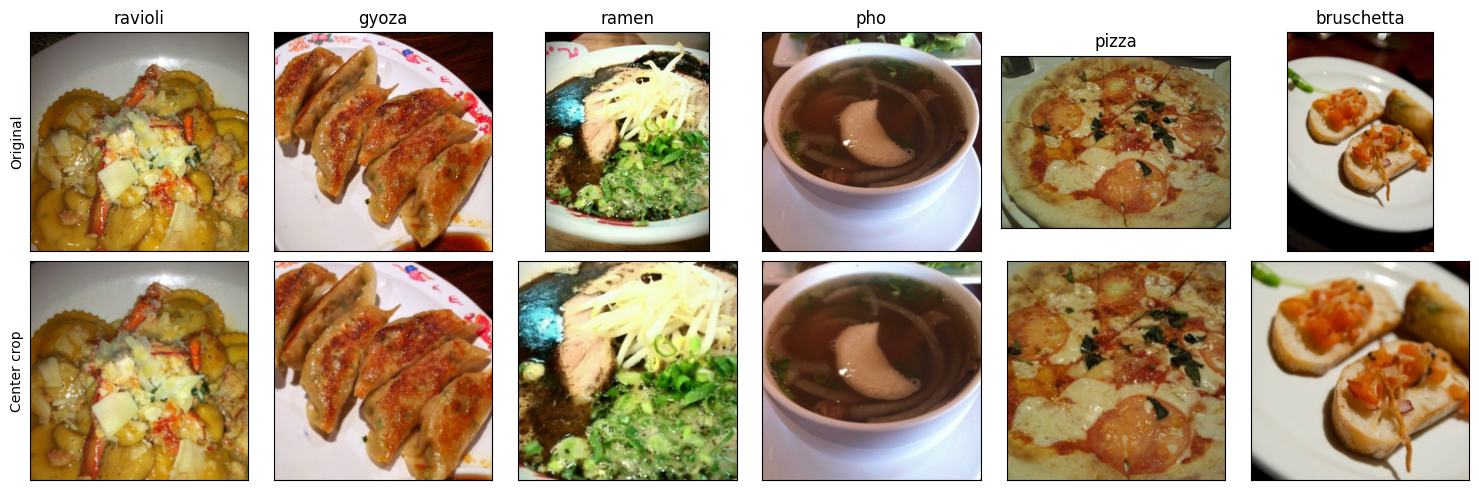

In [5]:
dish_names = ["ravioli", "gyoza", "ramen", "pho", "pizza", "bruschetta"]
train = data[data.split.eq("train")].sort_values("path")
geometry = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224)])
preprocess = ResNet18_Weights.IMAGENET1K_V1.transforms()
fig, axes = plt.subplots(2, len(dish_names), figsize=(15, 5))
for column, dish in enumerate(dish_names):
    path = train.loc[train.dish.eq(dish), "path"].iloc[0]
    with Image.open(ROOT / path) as image:
        rgb = image.convert("RGB")
    for row, view in enumerate((rgb, geometry(rgb))):
        axes[row, column].imshow(view)
        axes[row, column].set_xticks([])
        axes[row, column].set_yticks([])
    axes[0, column].set_title(dish)
axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Center crop")
fig.tight_layout()
fig.savefig(ART / "training_gallery.png", dpi=120, bbox_inches="tight")
plt.show()
plt.close(fig)

## Follow one pixel into the tensor

In Project 02 one grayscale value described a pixel. Here the same location has red, green, and blue values. A **tensor** is the numerical array the model receives. PyTorch arranges one image as channels × height × width. RGB numbers range from 0 to 255. I scale each channel to [0, 1], subtract its ImageNet mean, then divide by its ImageNet standard deviation. Using the same input convention for scratch and transfer runs makes their results easier to compare. Estimating channel statistics from our own training photos is another reasonable choice for a scratch-only experiment.

In [6]:
example = train.loc[train.dish.eq("ramen"), "path"].iloc[0]
with Image.open(ROOT / example) as image:
    rgb = image.convert("RGB")
raw = geometry(rgb).getpixel((112, 112))
tensor = preprocess(rgb)
expected = (torch.tensor(raw) / 255 - torch.tensor(preprocess.mean)) / torch.tensor(preprocess.std)
torch.testing.assert_close(tensor[:, 112, 112], expected)
print("Photo:", example, "| Original dimensions:", rgb.size)
print("Tensor:", tuple(tensor.shape), tensor.dtype)
print("Center RGB:", raw, "| Scaled:", [round(n / 255, 3) for n in raw])
print("Normalized:", [round(n.item(), 3) for n in tensor[:, 112, 112]])

Photo: images/ramen/1002305.jpg | Original dimensions: (384, 512)
Tensor: (3, 224, 224) torch.float32
Center RGB: (131, 132, 56) | Scaled: [0.514, 0.518, 0.22]
Normalized: [0.125, 0.275, -0.828]


## Time a training step on real food photos

I start with ResNet-18 because I can keep its architecture fixed while changing initialization and which layers learn. A **skip connection** adds a block's input, or a projection of it, to the block's output. In Session 2 I can inspect that addition directly. A small custom CNN would be cheaper to train but would also change the architecture in the scratch-versus-pretrained comparison. One Food-101 project uses InceptionV3 in Keras; another uses MobileNetV3-Large with PyTorch Lightning and exports to ONNX. MobileNet is especially relevant when model size matters. [Original ResNet paper](https://arxiv.org/abs/1512.03385) · [InceptionV3 example](https://github.com/DucLeTrong/food101-classification) · [MobileNetV3 example](https://github.com/yueyang-yin/food-101)

For this CPU estimate I use random weights and a 101-output classifier. A **batch** is the group of images used for one update. One **epoch** is one pass through the training set. I include image decoding, preprocessing, prediction, loss, backpropagation, and the optimizer update. Backpropagation computes a gradient for each trainable weight; the optimizer uses those gradients to update it. I compare 224 pixels with 160 pixels because the smaller input saves work but can lose fine food details. The timer answers the cost question. Validation accuracy will answer the recognition question later.

I use eight images per update and at most four PyTorch CPU threads as a modest laptop baseline. Larger batches use more memory. I use SGD with momentum here because it gives me a repeatable timing recipe with little per-weight bookkeeping. Adam is an alternative that adapts the step size for individual weights. Choosing the best optimizer for accuracy belongs in a training experiment. Three warm-up updates let the runtime initialize before I measure the next twelve.

In [ ]:
class FoodPhotos(Dataset):
    def __init__(self, records, transform):
        self.records = records
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        relative_path, label = self.records[index]
        with Image.open(ROOT / relative_path) as image:
            return self.transform(image.convert("RGB")), label

batch_size, warmup, measured = 8, 3, 12
torch.set_num_threads(min(4, torch.get_num_threads()))
sample = train.sample(n=batch_size * (warmup + measured), random_state=SEED)
records = list(sample[["path", "class_id"]].itertuples(index=False, name=None))

def time_training(crop):
    transform = ResNet18_Weights.IMAGENET1K_V1.transforms(
        crop_size=crop, resize_size=round(crop * 256 / 224))
    batches = iter(DataLoader(FoodPhotos(records, transform), batch_size=batch_size, num_workers=0))
    torch.manual_seed(SEED)
    model = resnet18(weights=None, num_classes=len(classes)).train()
    optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
    times = []
    for step in range(warmup + measured):
        start = perf_counter()
        images, labels = next(batches)
        optimizer.zero_grad(set_to_none=True)
        loss = torch.nn.functional.cross_entropy(model(images), labels)
        loss.backward()
        optimizer.step()
        elapsed = perf_counter() - start
        assert torch.isfinite(loss).item()
        if step >= warmup:
            times.append(elapsed)
    rate = batch_size * len(times) / sum(times)
    return {"crop": crop, "images_per_second": rate,
            "median_step_s": statistics.median(times), "step_seconds": times,
            "full_epoch_minutes": len(train) / rate / 60,
            "pilot_epoch_minutes": (25 * len(classes)) / rate / 60}

# Both crop sizes start with the same recently read JPEG files.
for relative_path, _ in records:
    (ROOT / relative_path).read_bytes()

timings = [time_training(crop) for crop in (224, 160)]
print(pd.DataFrame(timings).drop(columns="step_seconds").round(2).to_string(index=False))

 crop  images_per_second  median_step_s  full_epoch_minutes  pilot_epoch_minutes
  224               6.75           1.14              162.06                 6.24
  160              12.03           0.68               90.94                 3.50


## Record the laptop timing

I kept the 25-photos-per-dish estimate as a reference for a CPU-only run. The 224-pixel laptop estimate is 162 minutes per full training epoch. I chose Colab for the main experiment so every model can train at 224 × 224 on all eligible photos. GPU allocation and runtime speed are measured in Session 02.

In [8]:
report = {
    "seed": SEED, "manifest_sha256": manifest_digest, "official_counts": data.official_split.value_counts().to_dict(),
    "split_counts": split_counts, "class_count": len(classes),
    "exact_duplicate_groups": int(duplicates.gt(1).sum()),
    "photos_in_duplicate_groups": int(duplicates[duplicates.gt(1)].sum()),
    "conflicting_label_groups": len(conflicts),
    "excluded_by_reason": data.loc[data.split.eq("excluded"), "exclusion_reason"].value_counts().to_dict(),
    "source_modes": data["mode"].value_counts().to_dict(),
    "minimum_class_train_count": int(counts.train.min()),
    "maximum_class_train_count": int(counts.train.max()),
    "timing_protocol": {"model": "randomly initialized ResNet-18, 101 classes", "device": "cpu",
                        "processor": platform.processor(), "platform": platform.platform(),
                        "torch": str(torch.__version__), "torchvision": str(torchvision.__version__),
                        "torch_threads": torch.get_num_threads(), "loader_workers": 0,
                        "batch_size": batch_size, "warmup_batches": warmup,
                        "timed_batches": measured, "optimizer": "SGD, lr=0.01, momentum=0.9",
                        "timed_path": "read JPEG through optimizer step; files may be cached"},
    "timings": timings, "proposed_pilot_images_per_class": 25,
}
save_json("session1_audit.json", report)
print("Saved audit, timing observations, class map, gallery and split manifest.")

Saved audit, timing observations, class map, gallery and split manifest.


## What I’m taking into Session 02

The audit changed my starting count. I set aside 22 training entries with an exact match in the official test set and four more with conflicting labels. One photo was filed under both omelette and pancakes. That leaves **65,624 training photos**, **10,100 validation photos**, and the **25,250 official test photos**. Each validation class has exactly 100 examples.

The pizza in the gallery is a reminder to inspect preprocessing. I can see the full outline in the original, while the center crop keeps the toppings and cuts off much of the crust. I’ll run Session 02 on a Colab GPU with **224 × 224 crops, all 65,624 training images, and all 10,100 validation images**. The larger crop keeps more input pixels for fine details, and using every eligible photo gives the scratch model more examples per dish. The test set stays reserved. Session 02 measures the assigned GPU, chooses a time budget, and saves its progress to Drive after each epoch.